In [22]:
#!/usr/bin/env python3
# -*- coding: utf-8 -*-

#  Copyright (c) 2021 - 2022.  FlexibleLecture@Linkedin
#  All rights reserved.

# Created By  : FlexibleLecture@Linkedin
# Created Date: 2/3/2022
# version ='1.0'

# Demo: Solving Equality Constrained Analytic Center By Infeasible Start Newton Method - I : Feasible and Lower Bounded Problem

In the text book book-convex-2004, section 10.3, the infeasible start Newton method was used to solve the equality constrained analytic center problem,

\begin{equation}
\begin{array}{rcl}
\mathbf{miniminze} & & -\displaystyle{\sum_{i=1}^{n}}\log x_i \\
\mathbf{subject to} & & Ax = b\\ 
\end{array}
\end{equation}
where $A \in R^{m\times n}$, with implicit constraint $x\succ 0$.

However, the above equality constrained analytic center problem may be unbounded and may not be feasible. For example, in the first part of the demo two instances of the problem with different equality constraint when $n=2, m=1$ are provided, where one instance is lower bounded, but the other is unbounded.


In the second part of the demo, to make the problem feasible and lower bounded, $A$ and $b$ are generated in the following steps in order to satisfy the optimality conditions: $\exists x^*$ and $\nu^*$

\begin{equation}
\begin{array}{rcl}
\left[\dfrac{1}{x^*}\right] & = & A^T\nu^* \\
Ax^* & = & b \\
x^* & \succ & 0 \\
\end{array}
\end{equation}

\begin{enumerate}
\item Generate $A\in \mathbf{U}(0,1)^{p\times n}$ randomly
\item Generate $\nu \in \mathbf{U}(0, 1)^{m}$ randomly
\item Let $x_*=\dfrac{1}{A^T\nu}$
\item Let $b=Ax^*$
\end{enumerate}

In the experiment, $m=500$, $n=1000$, the initial primal and dual points are $x^{(0)}=\mathbf{1}$ and $\nu=\mathbf{0}$. The KKT equation is

 $$
    \begin{array}{rccl}
    \left[\begin{array}{cc}
    \nabla^2 f(x) & A^T \\
    A & 0 \\
     \end{array}
     \right] &
     \left[\begin{array}{c}
      \Delta x_{pd} \\
      \Delta \nu_{pv}
     \end{array}
     \right] &
     = &
     -\left[
       \begin{array}{c}
        r_{dual} \\
        r_{pri} \\
       \end{array}
      \right] \\
    \end{array}
$$
where $r_{dual}=\nabla f(x)+A^Tx$, $r_{pri}=Ax-b$

In the \textit{Infeasible start Newton Method}, the Newton iteration exits only when
$$
 \parallel r_{pri}  \parallel \leq \zeta=10^{-12} \mathbf{    and   } \parallel r_{dual} \parallel \leq \epsilon=10^{-12}
$$


In [23]:
import numpy as np
import sys
import matplotlib.pyplot as plt

$f(x)=-\sum_{i=1}^n\log x_i$

$\nabla f(x)=\dfrac{1}{x}$

$\nabla^2 f(x)= diag(\dfrac{1}{x^2})$

it requires $x\succ 0$

In [24]:
def my_f(x):
    """
    $f(x)=-\sum_{i=1}^n\log x_i$
    :param x:
    :return:
    """
    return -np.sum(np.log(x))


def my_derivative_f(x):
    """
    $\nabla f(x)=\dfrac{1}{x}$
    :param x:
    :return:
    """
    return -1 / x


def my_hessian_f(x):
    """
    $\nabla^2 f(x)= diag(\dfrac{1}{x^2})$
    :param x:
    :return:
    """
    return np.diag(1 / (np.squeeze(x) ** 2))


def my_f_feasible(x):
    """
    it requires $x\succ 0$
    :param x:
    :return:
    """
    return np.all(x > 0)

 calculate the primal-dual step by solving the KKT equations
    $$
    \begin{array}{rccl}
    \left[\begin{array}{cc}
    \nabla^2 f(x) & A^T \\
    A & 0 \\
     \end{array}
     \right] &
     \left[\begin{array}{c}
      \Delta x_{pd} \\
      \Delta \nu_{pv}
     \end{array}
     \right] &
     = &
     -\left[
       \begin{array}{c}
        r_{dual} \\
        r_{pri} \\
       \end{array}
      \right] \\
    \end{array}
    $$
    where
    $r_{dual}=\nabla f(x)+A^Tx$, $r_{pri}=Ax-b$

In [25]:
def primal_dual_newton_step(x, nu, A, b):
    """
    calculate the primal-dual step by solving the KKT equations
    $$
    \begin{array}{rccl}
    \left[\begin{array}{cc}
    \nabla^2 f(x) & A^T \\
    A & 0 \\
     \end{array}
     \right] &
     \left[\begin{array}{c}
      \Delta x_{pd} \\
      \Delta \nu_{pv}
     \end{array}
     \right] &
     = &
     -\left[
       \begin{array}{c}
        r_{dual} \\
        r_{pri} \\
       \end{array}
      \right]
    \end{array}
    $$
    where
    $r_{dual}=\nabla f(x)+A^Tx$, $r_{pri}=Ax-b$
    :param x:
    :param nu:
    :param A:
    :param b:
    :return:
    """
    KKT_matrix = np.block([[my_hessian_f(x), A.T], [A, np.zeros((A.shape[0], A.shape[0]))]])
    minus_residual_dual_primal = -1 * np.block([[my_derivative_f(x) + (A.T @ nu)], [A @ x - b]])
    if np.linalg.cond(KKT_matrix) < 1 / sys.float_info.epsilon:
        newton_step = np.linalg.inv(KKT_matrix) @ minus_residual_dual_primal
        primal_step = newton_step[0: len(x)]
        dual_step = newton_step[len(x):]
        return primal_step, dual_step
    else:
        raise RuntimeError("KKT matrix is not invertible.")

$r=\left[\begin{array}{c} r_{dual} \\ r_{pri}\\ \end{array} \right]$

$|r_{pri}|, |r_{dual}|$

$|r|=\parallel \left[\begin{array}{c} r_{dual} \\ r_{pri}\\ \end{array} \right] \parallel _2$

In [26]:
def residual_f(x, nu, A, b):
    """
    $r=\left[\begin{array}{c} r_{dual} \\ r_{pri}\\ \end{array} \right]$
    :param x:
    :param nu:
    :param A:
    :param b:
    :return:
    """
    r_dual = my_derivative_f(x) + A.T @ nu
    r_pri = A @ x - b
    return np.block([[r_dual], [r_pri]])


def residual_dual_primal_norm_f(x, nu, A, b):
    """
    $|r_{pri}|, |r_{dual}|$
    :param x:
    :param nu:
    :param A:
    :param b:
    :return:
    """
    residual = residual_f(x, nu, A, b)
    return np.linalg.norm(residual[0: len(x)]), np.linalg.norm(residual[len(x):])


def residual_norm_f(x, nu, A, b):
    """
    $|r|=\parallel \left[\begin{array}{c} r_{dual} \\ r_{pri}\\ \end{array} \right] \parallel _2$
    :param x:
    :param nu:
    :param A:
    :param b:
    :return:
    """
    residual = residual_f(x, nu, A, b)
    return np.linalg.norm(residual)

Backtracking line search implementation, see to Algorithm 9.2 in the textbook

In [27]:
def backtracking_line_search(x, nu, d_x, d_nu, alpha, beta, args):
    """
    Backtracking line search implementation, see to Algorithm 9.2 in the textbook
    :param x:
    :param nu:
    :param d_x:
    :param d_nu:
    :param alpha:
    :param beta:
    :param args:
    :return:
    """
    t = 1
    r = residual_norm_f
    while (not my_f_feasible(x + d_x * t)) \
            or r(x + t * d_x, nu + t * d_nu, *args) > (1 - alpha * t) * r(x, nu, *args):
        t = beta * t
    return t

plot two instance of problems, one is unbounded thus infeasible; the other bounded thus feasible.

Refer to FlexibleLecture Note on how to generate model parameters, A, b, so that the problem is feasible

In [28]:
def plot_two_instance_problems(seed):
    """
    plot two instance of problems, one is unbounded thus infeasible; the other bounded thus feasible.
    Refer to FlexibleLecture Note on how to generate model parameters, A, b, so that the problem is feasible
    :param seed:
    :return:
    """
    n = 2
    m = 1
    np.random.seed(seed)
    A = np.random.rand(m, n)
    nu_asterisk = np.random.rand(m, 1)
    inv_x_asterisk = A.T @ nu_asterisk
    x_asterisk = 1 / inv_x_asterisk
    b = A @ x_asterisk

    x1_max = (b / A[0, 0]).item()
    x2_max = (b / A[0, 1]).item()

    delta = 0.1
    x = np.arange(0, x1_max, delta)
    y = np.arange(0, x2_max, delta)
    X, Y = np.meshgrid(x, y)
    Z = np.zeros(X.shape)

    for x1_i in range(len(x)):
        for x2_i in range(len(y)):
            x1 = x[x1_i]
            x2 = y[x2_i]
            Z[x2_i][x1_i] = my_f(np.array([[x1], [x2]]))

    ax1 = plt.subplot(1, 1, 1)
    levels = np.arange(-10, 20, 0.1)
    CS = ax1.contour(X, Y, Z, linestyles='dashed', levels=levels)
    ax1.clabel(CS, fontsize=6, inline=True)

    x1 = np.linspace(0, x1_max, num=10).tolist()
    x2 = [(b - A[0, 0] * t).item() / A[0, 1] for t in x1]
    ax1.plot(x1, x2, linestyle='dashed',
             label=r'Ax=b: ${:.2f}x_1 + {:.2f}x_2$ = {:.2f} (lower bounded)'.format(A[0, 0], A[0, 1], b.item()),
             color='green')

    x1 = np.linspace(0, x1_max, num=10).tolist()
    x2 = [1 + 0.5 * t for t in x1]
    ax1.plot(x1, x2, linestyle='dashed', label=r'Ax=b: ${:.2f}x_1 - {:.2f}x_2$ = {:.2f} (unbounded)'.format(0.5, 1, -1),
             color='red')

    ax1.grid()
    ax1.set_xlabel(r'$x_1$')
    ax1.set_ylabel(r'$x_2$')
    ax1.legend()
    plt.show()

plot the progress of infeasible start Newton method on a feasible equality constrained analytic centering problem

Refer to FlexibleLecture Note for how to generate feasible model parameters

In [29]:
def plot_infeasible_start_newton_method_convergence(n, m, seed):
    """
    plot the progress of infeasible start Newton method on a feasible equality constrained analytic centering problem
    Refer to FlexibleLecture Note for how to generate feasible model parameters
    :param n:
    :param m:
    :param seed:
    :return:
    """
    np.random.seed(seed)
    A = np.random.rand(m, n)
    nu_asterisk = np.random.rand(m, 1)
    inv_x_asterisk = A.T @ nu_asterisk
    x_asterisk = 1 / inv_x_asterisk
    b = A @ x_asterisk

    alpha = 0.01
    beta = 0.5
    epsilon = 1e-12
    zeta = 1e-12  # quantization error checking Ax = b
    x0 = np.ones((n, 1))
    nu0 = np.zeros((m, 1))

    x = x0
    nu = nu0
    args = (A, b)
    r_dual_norms = []
    r_prim_norms = []
    ts = []
    iteration = 0
    while True:
        r_dual_norm, r_prim_norm = residual_dual_primal_norm_f(x, nu, A, b)
        d_x, d_nu = primal_dual_newton_step(x, nu, A, b)
        t = backtracking_line_search(x, nu, d_x, d_nu, alpha, beta, args)

        # log the statistics
        r_dual_norms.append(r_dual_norm)
        r_prim_norms.append(r_prim_norm)
        ts.append(t)

        x = x + t * d_x
        nu = nu + t * d_nu

        r_pri = np.linalg.norm(A @ x - b)
        r_dual = residual_norm_f(x, nu, A, b)
        print('Info: iteration={}, |r_pri|={}, |r_dual|={}'.format(iteration, r_pri, r_dual))
        iteration = iteration + 1

        if r_pri < zeta and r_dual <= epsilon:
            break

    r_dual_norm, r_prim_norm = residual_dual_primal_norm_f(x, nu, A, b)
    r_dual_norms.append(r_dual_norm)
    r_prim_norms.append(r_prim_norm)
    print('Info: x_p, |diff| = {}'.format(np.linalg.norm(x - x_asterisk)))
    print('Info: nu_p, |diff| = {}'.format(np.linalg.norm(nu - nu_asterisk)))

    ax = plt.subplot(1, 2, 1)
    ax.semilogy(r_prim_norms, marker='+', label=r'$\parallel r_{pri} \parallel$')
    ax.semilogy(r_dual_norms, marker='x', label=r'$\parallel r_{dual} \parallel$')
    ax.legend()
    ax.grid()
    ax.set_xlabel('iteration')
    ax.set_ylabel('residual')

    ax = plt.subplot(1, 2, 2)
    ax.plot(ts, marker='+', label='t: step length')
    ax.legend()
    ax.grid()
    ax.set_xlabel('iteration')
    ax.set_ylabel('t: step length')
    plt.show()

<ipython-input-24-b1aabdfc25b3>:7: RuntimeWarning: divide by zero encountered in log
  return -np.sum(np.log(x))


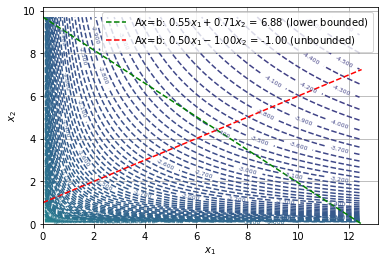

In [30]:
if __name__ == "__main__":
    plot_two_instance_problems(seed=3)


Info: iteration=0, |r_pri|=5535.069821454916, |r_dual|=5535.158620502352
Info: iteration=1, |r_pri|=2767.534910727449, |r_dual|=2767.910171024752
Info: iteration=2, |r_pri|=1383.7674553637223, |r_dual|=1386.0404725502456
Info: iteration=3, |r_pri|=691.8837276818575, |r_dual|=705.7600205020343
Info: iteration=4, |r_pri|=345.9418638409335, |r_dual|=415.03967566373655
Info: iteration=5, |r_pri|=172.97093192046663, |r_dual|=370.04108743984574
Info: iteration=6, |r_pri|=129.72819894035845, |r_dual|=317.0083107704857
Info: iteration=7, |r_pri|=97.29614920526653, |r_dual|=276.22256356787807
Info: iteration=8, |r_pri|=72.9721119039492, |r_dual|=242.22118908110468
Info: iteration=9, |r_pri|=54.72908392796241, |r_dual|=211.51876388826446
Info: iteration=10, |r_pri|=41.04681294597248, |r_dual|=182.4588451122896
Info: iteration=11, |r_pri|=20.523406472985215, |r_dual|=170.24529377042558
Info: iteration=12, |r_pri|=6.683634081142433e-13, |r_dual|=139.07581402357877
Info: iteration=13, |r_pri|=2.091

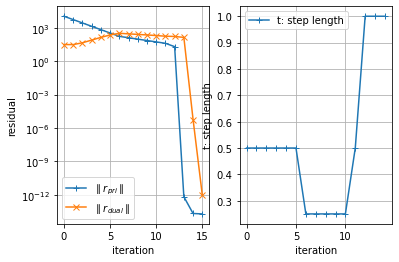

In [31]:
if __name__ == "__main__":
    n = 1000
    m = 500
    seed = 2
    plot_infeasible_start_newton_method_convergence(n=n, m=m, seed=seed)